# 16 — Reinterpreting the anchored idle results

Notebook 15 read the anchored runs as one pooled flip rate per wait: a ~1.2% floor, no steady
growth, and a 2.4% spike at L = 16 put down to chance. This notebook looks at the same shots one
by one: in each shot, which of the 8 targets flipped.

**What the program allows** (`calibration_experiments.anchored_idle_program`). Every target is
coupled to one shared anchor qubit, held in |0⟩, by ZZPhase(+½) right after its preparation and
uncoupled by ZZPhase(−½) at the end:

```
T0…T7: ─H─ZZ(+½)──────── wait: L transport layers ────────ZZ(−½)─Z^par─H─M
          │                                                │
A    : ───ZZ(+½)×8 ──ZZ(S0)────────────────────────────────ZZ(−½)×8
```

With the anchor in |0⟩ the two phases cancel. If the anchor flips between a target's coupling
and its uncoupling, they add up to a Z on that target, which flips it in the X basis. One anchor
flip therefore flips several targets in the same shot, and which ones depends on when it
happened, since targets are coupled and uncoupled in the order 0…7:
- during the coupling sweep → the targets coupled before it: a **prefix** (`11100000`);
- during the wait → **all 8** (`11111111`);
- during the uncoupling sweep → the targets uncoupled after it: a **suffix** (`00000111`).

In the Z basis the targets sit in |0⟩, which a Z does not change: no such flips. The transport and
measure-and-reset designs have no anchor: no such flips either. Idle dephasing acts on each target
on its own, so it flips targets one at a time.

**Source:** `python -m qec_timing.hardware.cli collect` → `results/hardware/h2_1e_idle_flip_patterns.json`
(per-shot flip patterns of every returned idle job; H2-1E via aqora, `q_sq`).

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
from scipy.stats import beta
cp = lambda k, n: (beta.ppf(.025, k, n - k + 1) if k else 0.0, beta.ppf(.975, k + 1, n - k))
runs = json.loads((R / "hardware" / "h2_1e_idle_flip_patterns.json").read_text())["runs"]

def shots_of(run):
    """One row per shot: the 8 target flips (0/1)."""
    return np.array([[int(c) for c in pat] for pat, n in run["patterns"].items() for _ in range(n)])

def pooled(design, basis, shots=None):
    sel = [r for r in runs.values() if r["design"] == design and r["basis"] == basis
           and (shots is None or r["shots"] == shots)]
    return np.vstack([shots_of(r) for r in sel])

def kind(pat):
    k = pat.count("1"); n = len(pat)
    if k < 2: return None
    if k == n: return "all"
    if pat == "1" * k + "0" * (n - k): return "prefix"
    if pat == "0" * (n - k) + "1" * k: return "suffix"
    return "other"

for name, (d, b, s) in {"anchored X, 1000-shot runs": ("anchored", "X", 1000), "anchored Z": ("anchored", "Z", None),
                        "transport X": ("transport", "X", None), "measure-and-reset X": ("measure-and-reset", "X", None)}.items():
    m = pooled(d, b, s).sum(axis=1)
    print(f"{name:27s} {len(m):5d} shots: {np.mean(m == 1):.4f} with one flipped target, {np.mean(m >= 2):.4f} with 2 or more")

anchored X, 1000-shot runs   5000 shots: 0.0310 with one flipped target, 0.0144 with 2 or more
anchored Z                   1000 shots: 0.0250 with one flipped target, 0.0000 with 2 or more
transport X                   500 shots: 0.0100 with one flipped target, 0.0000 with 2 or more
measure-and-reset X           700 shots: 0.0043 with one flipped target, 0.0000 with 2 or more


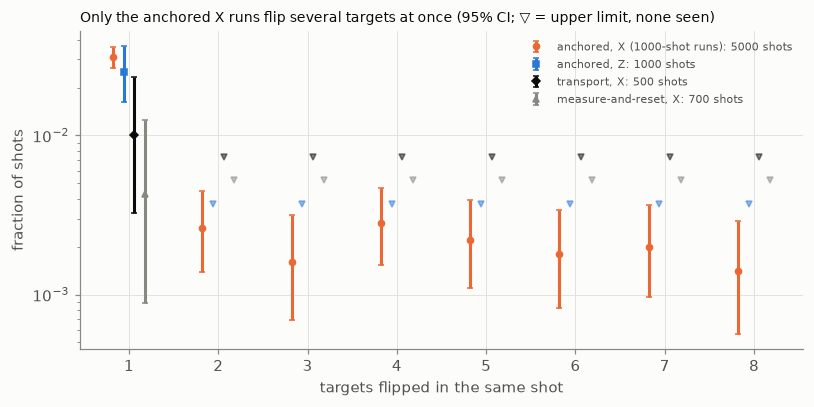

In [3]:
groups = [("anchored, X (1000-shot runs)", pooled("anchored", "X", 1000), P.SERIES[1], "o"),
          ("anchored, Z", pooled("anchored", "Z"), P.SERIES[0], "s"),
          ("transport, X", pooled("transport", "X"), P.INK, "D"),
          ("measure-and-reset, X", pooled("measure-and-reset", "X"), P.MUTED, "^")]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (lab, a, col, mk) in enumerate(groups):
    m = a.sum(axis=1); ks = np.arange(1, 9); c = np.array([(m == k).sum() for k in ks])
    ci = np.array([cp(int(v), len(m)) for v in c]).T; f = c / len(m); x = ks + 0.12 * (i - 1.5)
    ok = c > 0
    ax.errorbar(x[ok], f[ok], yerr=[(f - ci[0])[ok], (ci[1] - f)[ok]], fmt=mk, color=col, capsize=2, ms=4,
                label=f"{lab}: {len(m)} shots")
    ax.plot(x[~ok], ci[1][~ok], "v", color=col, ms=4, alpha=0.5)
ax.set_yscale("log"); ax.set_xticks(range(1, 9))
ax.set_xlabel("targets flipped in the same shot"); ax.set_ylabel("fraction of shots")
ax.set_title("Only the anchored X runs flip several targets at once (95% CI; ▽ = upper limit, none seen)", loc="left", fontsize=9)
ax.legend(fontsize=7.5)
fig.tight_layout()
P.save(fig, "16_reinterpreting_anchoring_results_1")

**Reading.**
- *Measured:* in the anchored X runs about 1 shot in 70 (1.4%) has 2 to 8 targets flipped together. No
  shot of the anchored Z, transport or measure-and-reset runs has more than one.
- *Interp.:* that is the anchor's signature: an error shared by all targets, present only where an
  anchor exists and only in the basis where a Z on the targets shows.

In [4]:
from collections import Counter
order = ["prefix", "all", "suffix", "other"]
cnt = Counter(); seen = Counter()
for r in runs.values():
    if r["design"] == "anchored" and r["basis"] == "X":
        for pat, n in r["patterns"].items():
            if kind(pat):
                cnt[kind(pat)] += n; seen[pat] += n
n_multi = sum(cnt.values())
print(f"{n_multi} anchored X shots with 2+ flipped targets:", {k: cnt[k] for k in order})
print("most common:", ", ".join(f"{p} ×{n}" for p, n in seen.most_common(8)))
# Chance that a shot's pattern is a prefix, all or suffix if its k flipped targets were placed at random.
from math import comb
chance = sum(n * (1 if pat.count("1") == 8 else 2 / comb(8, pat.count("1"))) for pat, n in seen.items()) / n_multi
print(f"contiguous from an end: {1 - cnt['other'] / n_multi:.2f} of these shots; if the flipped targets were "
      f"random, about {chance:.2f}")

78 anchored X shots with 2+ flipped targets: {'prefix': 16, 'all': 8, 'suffix': 41, 'other': 13}
most common: 00011111 ×9, 00001111 ×8, 01111111 ×8, 11111111 ×8, 00000111 ×6, 00000011 ×5, 00111111 ×5, 11000000 ×4
contiguous from an end: 0.83 of these shots; if the flipped targets were random, about 0.18


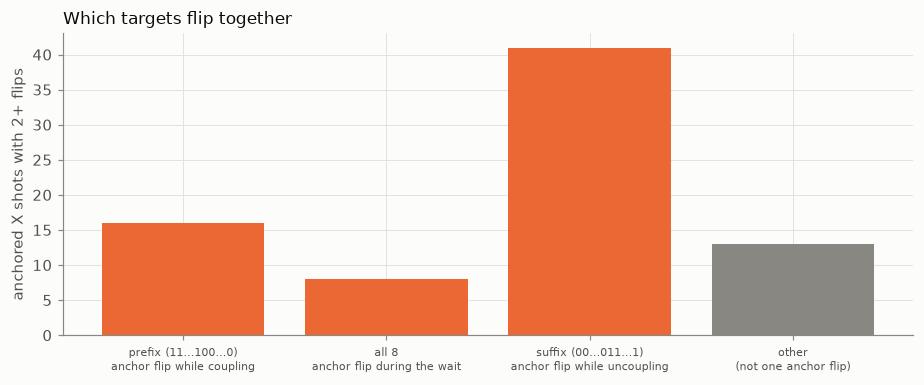

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
lab = {"prefix": "prefix (11…100…0)\nanchor flip while coupling", "all": "all 8\nanchor flip during the wait",
       "suffix": "suffix (00…011…1)\nanchor flip while uncoupling", "other": "other\n(not one anchor flip)"}
cols = [P.SERIES[1], P.SERIES[1], P.SERIES[1], P.MUTED]
ax.bar(range(4), [cnt[k] for k in order], color=cols)
ax.set_xticks(range(4), [lab[k] for k in order], fontsize=7.5)
ax.set_ylabel("anchored X shots with 2+ flips")
ax.set_title("Which targets flip together", loc="left")
fig.tight_layout()
P.save(fig, "16_reinterpreting_anchoring_results_2")

**Reading.**
- *Measured:* most of the multi-target shots flip a block of targets that starts at target 0,
  ends at target 7, or is all 8. Picked at random, few blocks would have that shape (the
  printed chance above).
- *Interp.:* the blocks match one anchor flip during the coupling sweep, the wait or the
  uncoupling sweep. The "other" shots (two separate blocks and the like) fit two errors, or an
  anchor flip plus an ordinary single flip.

In [6]:
long = sorted((r for r in runs.values() if r["design"] == "anchored" and r["basis"] == "X" and r["shots"] == 1000),
              key=lambda r: r["layers"])
L = np.array([r["layers"] for r in long]); x = np.where(L == 0, 0.7, L)
rng = np.random.default_rng(16)
rows = []
for r in long:
    a = shots_of(r); m = a.sum(axis=1); n = len(m)
    tot = a.mean()
    boot = np.array([a[rng.integers(0, n, n)].mean() for _ in range(4000)])
    naive = cp(int(a.sum()), a.size)
    one = int((m == 1).sum()); burst = m[m >= 2].sum() / a.size
    rows.append(dict(L=r["layers"], n=n, tot=tot, boot=np.percentile(boot, [2.5, 97.5]), naive=naive,
                     one=one, one_ci=cp(one, n), burst=burst))
    print(f"L = {r['layers']:>3}: all flips {100 * tot:.2f}%  (95%: shots resampled {100 * rows[-1]['boot'][0]:.2f}-{100 * rows[-1]['boot'][1]:.2f}, "
          f"targets as independent {100 * naive[0]:.2f}-{100 * naive[1]:.2f});  from 2+ flip shots {100 * burst:.2f}%;  "
          f"single flips {one}/{n} shots")

L =   0: all flips 1.03%  (95%: shots resampled 0.60-1.50, targets as independent 0.82-1.27);  from 2+ flip shots 0.80%;  single flips 18/1000 shots
L =  16: all flips 1.16%  (95%: shots resampled 0.70-1.69, targets as independent 0.94-1.42);  from 2+ flip shots 0.85%;  single flips 25/1000 shots
L =  32: all flips 1.40%  (95%: shots resampled 0.86-1.99, targets as independent 1.15-1.68);  from 2+ flip shots 1.04%;  single flips 29/1000 shots


L =  64: all flips 1.50%  (95%: shots resampled 1.01-2.04, targets as independent 1.25-1.79);  from 2+ flip shots 1.09%;  single flips 33/1000 shots
L = 128: all flips 1.11%  (95%: shots resampled 0.78-1.51, targets as independent 0.89-1.37);  from 2+ flip shots 0.49%;  single flips 50/1000 shots


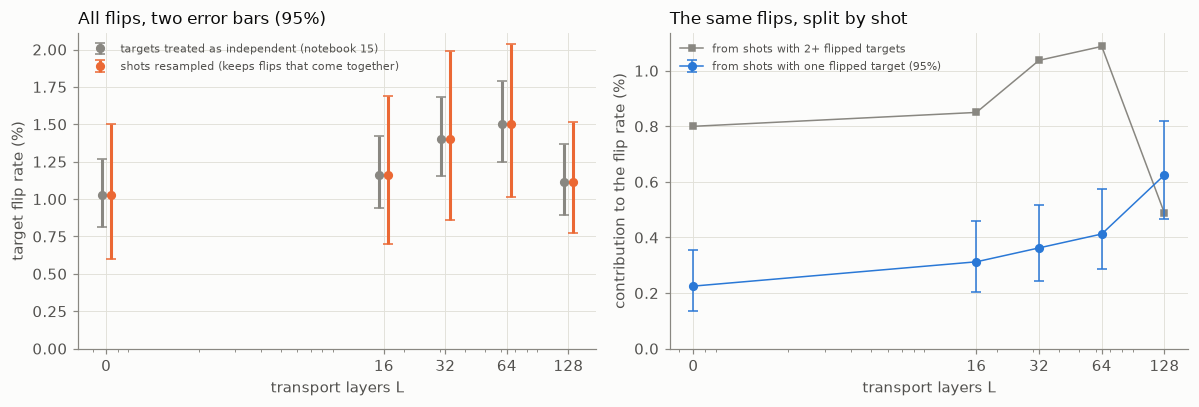

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
tot = np.array([r["tot"] for r in rows]); bo = np.array([r["boot"] for r in rows]).T; nv = np.array([r["naive"] for r in rows]).T
axes[0].errorbar(x * 0.95, 100 * tot, yerr=[100 * (tot - nv[0]), 100 * (nv[1] - tot)], fmt="o", color=P.MUTED, capsize=3,
                 label="targets treated as independent (notebook 15)")
axes[0].errorbar(x * 1.05, 100 * tot, yerr=[100 * (tot - bo[0]), 100 * (bo[1] - tot)], fmt="o", color=P.SERIES[1], capsize=3,
                 label="shots resampled (keeps flips that come together)")
axes[0].set_title("All flips, two error bars (95%)", loc="left"); axes[0].set_ylabel("target flip rate (%)")
burst = np.array([r["burst"] for r in rows]); one = np.array([r["one"] for r in rows]) / 1000 / 8
oci = np.array([r["one_ci"] for r in rows]).T / 8
axes[1].plot(x, 100 * burst, "s-", color=P.MUTED, ms=4, lw=1, label="from shots with 2+ flipped targets")
axes[1].errorbar(x, 100 * one, yerr=[100 * (one - oci[0]), 100 * (oci[1] - one)], fmt="o-", color=P.SERIES[0], capsize=3, lw=1,
                 label="from shots with one flipped target (95%)")
axes[1].set_title("The same flips, split by shot", loc="left"); axes[1].set_ylabel("contribution to the flip rate (%)")
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks([0.7, 16, 32, 64, 128], ["0", "16", "32", "64", "128"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xlabel("transport layers L"); ax.set_ylim(bottom=0)
    ax.legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
P.save(fig, "16_reinterpreting_anchoring_results_3")

In [8]:
from scipy.stats import chi2 as chi2_dist
k1 = np.array([r["one"] for r in rows]); n1 = np.array([r["n"] for r in rows])
p1 = k1 / n1; w = n1 / np.maximum(p1 * (1 - p1), 1e-9); c = (w * p1).sum() / w.sum(); chi = (w * (p1 - c) ** 2).sum()
print(f"single-flip shots per 1000: {k1.tolist()} at L = {L.tolist()}")
print(f"constant: chi2 {chi:.1f} on {len(L) - 1} dof, p = {chi2_dist.sf(chi, len(L) - 1):.4f}")
A = np.vstack([np.ones_like(L), L]).T; cov = np.linalg.inv(A.T @ (A * w[:, None])); b = cov @ A.T @ (w * p1)
print(f"straight line: {100 * b[0] / 8:.3f}% + {100 * b[1] / 8 * 1e3:.2f}e-3 % per layer, per target "
      f"(slope {b[1] / np.sqrt(cov[1, 1]):.1f} sigma from zero)")
spike = runs["idleA_X_L16@100"]["patterns"]
print("the 100-shot L = 16 run (notebook 15's spike):", {p: n for p, n in spike.items() if p != "0" * 8})

single-flip shots per 1000: [18, 25, 29, 33, 50] at L = [0, 16, 32, 64, 128]
constant: chi2 17.0 on 4 dof, p = 0.0019
straight line: 0.244% + 2.97e-3 % per layer, per target (slope 4.1 sigma from zero)
the 100-shot L = 16 run (notebook 15's spike): {'00001111': 1, '01111111': 1, '11111111': 1}


**Reading.**
- *Measured:* shots with 2+ flipped targets carry most of the anchored X flip rate (0.8–1.1% of
  1.0–1.5% up to L = 64; 0.5% of 1.1% at L = 128), and they make the rate noisier than the target-by-target intervals of notebook 15
  allow: resampling whole shots gives wider intervals. Notebook 15's spike at L = 16
  (19 flips in 800) is three such shots, with 4, 7 and 8 targets flipped.
- *Measured, found after looking (not yet a result):* the shots with exactly one flipped target
  become more frequent with L, from 18 to 50 per 1000 between L = 0 and 128, which a constant
  does not fit. Single flips are what idle dephasing would give. The trend was noticed in the
  data rather than predicted, so it needs a run designed for it before it counts.
- *Interp.:* the anchored floor and its scatter are mostly anchor errors, not idling. The
  conclusion of notebook 15, "no idle growth up to L = 128", came from the pooled rate, in which
  the anchor errors can hide a small idle signal.
- *Next:* test the single-flip trend with fresh shots, decided in advance: the same L grid,
  counting single-flip shots only, and with one anchor per target (or a few targets per anchor)
  so that one anchor error cannot flip many targets.